# ED408 — Statistical Machine Learning II Lab
## Experiment 8: Simulated Annealing for function optimisation

**Minimise** $f(x)=x^2+10\sin(x)$ on $[-10,10]$.

The function has two minima: a **local** one near $x\approx3.84$ ($f\approx8.32$) and the **global** one near $x\approx-1.31$ ($f\approx-7.95$), separated by a hill at $x\approx1.98$. A greedy search started on the right side gets stuck in the local basin. Simulated Annealing gets out because it sometimes accepts uphill moves:
$$P(\text{accept})=\begin{cases}1,&\Delta f\le 0\\ e^{-\Delta f/T},&\Delta f>0\end{cases}\qquad T_{k+1}=\alpha T_k .$$


Grid search:  x* = -1.3064,  f(x*) = -7.9458


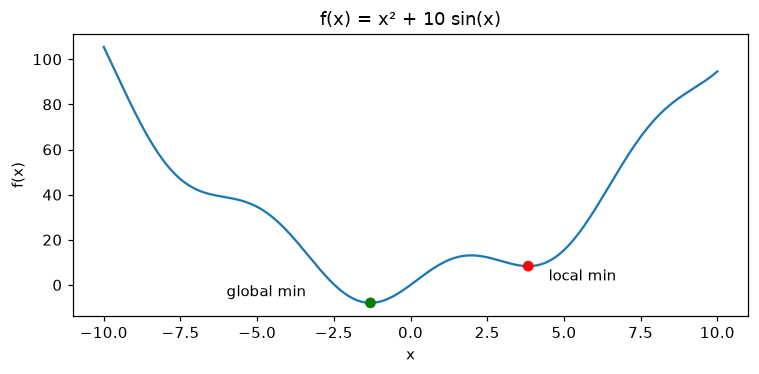

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

f = lambda x: x**2 + 10*np.sin(x)
LO, HI = -10, 10

# reference answer from a dense grid
grid = np.linspace(LO, HI, 200001)
x_true = grid[np.argmin(f(grid))]
print(f"Grid search:  x* = {x_true:.4f},  f(x*) = {f(x_true):.4f}")

plt.figure(figsize=(7, 3.5))
plt.plot(grid, f(grid))
plt.scatter([x_true, 3.8375], [f(x_true), f(3.8375)], c=["g", "r"], zorder=3)
plt.annotate("global min", (x_true, f(x_true)), xytext=(-6, -5))
plt.annotate("local min", (3.84, f(3.84)), xytext=(4.5, 2))
plt.title("f(x) = x² + 10 sin(x)"); plt.xlabel("x"); plt.ylabel("f(x)")
plt.tight_layout(); plt.show()

In [2]:
def simulated_annealing(f, x0, T0=10.0, alpha=0.95, T_min=1e-3, n_per_T=20, step=0.5, rng=None):
    rng = rng or np.random.default_rng()
    x, fx = x0, f(x0)
    best_x, best_f = x, fx
    T = T0
    hist = {"x": [], "f": [], "best": [], "T": []}
    worse_accepted = 0
    while T > T_min:
        for _ in range(n_per_T):
            xn = np.clip(x + rng.normal(0, step), LO, HI)   # random neighbour
            fn = f(xn)
            d = fn - fx
            if d <= 0 or rng.random() < np.exp(-d / T):
                worse_accepted += d > 0
                x, fx = xn, fn
                if fx < best_f:
                    best_x, best_f = x, fx
            hist["x"].append(x); hist["f"].append(fx)
            hist["best"].append(best_f); hist["T"].append(T)
        T *= alpha                                        # geometric cooling
    return best_x, best_f, hist, worse_accepted


def hill_climb(f, x0, n_iter, step=0.5, rng=None):
    """Greedy baseline: same neighbour rule, but only accepts improvements."""
    rng = rng or np.random.default_rng()
    x, fx = x0, f(x0)
    for _ in range(n_iter):
        xn = np.clip(x + rng.normal(0, step), LO, HI)
        if f(xn) < fx:
            x, fx = xn, f(xn)
    return x, fx


x0 = 8.0   # start on the wrong side of the hill
best_x, best_f, hist, n_worse = simulated_annealing(f, x0, rng=np.random.default_rng(1))
hc_x, hc_f = hill_climb(f, x0, len(hist["x"]), rng=np.random.default_rng(1))

print(f"Start x0 = {x0},  f(x0) = {f(x0):.4f},  iterations = {len(hist['x'])}")
print(f"Simulated Annealing : x = {best_x:.4f},  f = {best_f:.4f}   (uphill moves accepted: {n_worse})")
print(f"Hill climbing       : x = {hc_x:.4f},  f = {hc_f:.4f}")

Start x0 = 8.0,  f(x0) = 73.8936,  iterations = 3600
Simulated Annealing : x = -1.3063,  f = -7.9458   (uphill moves accepted: 556)
Hill climbing       : x = 3.8375,  f = 8.3156


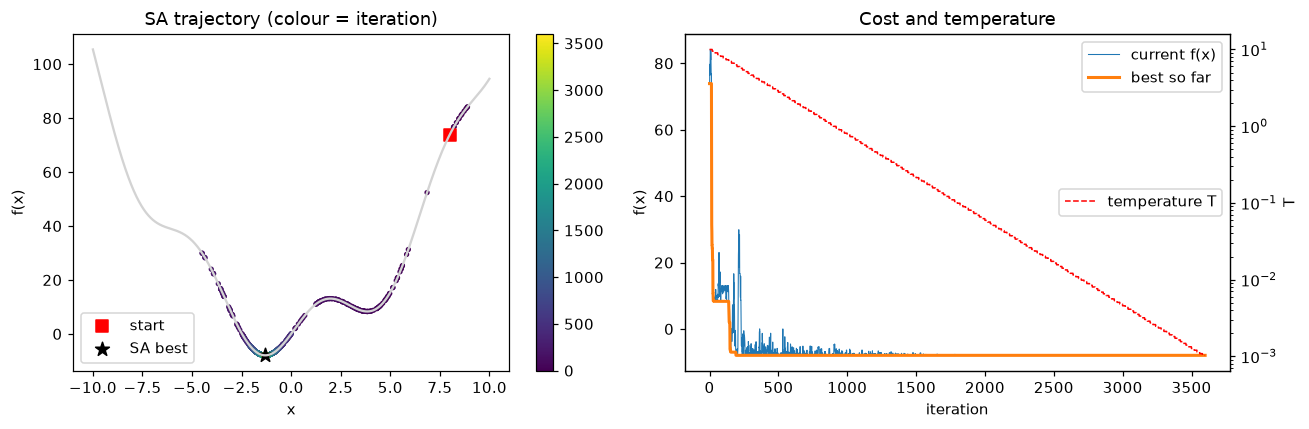

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(grid, f(grid), c="lightgray")
sc = ax[0].scatter(hist["x"], hist["f"], c=np.arange(len(hist["x"])), cmap="viridis", s=6)
ax[0].scatter(x0, f(x0), c="r", s=60, marker="s", label="start")
ax[0].scatter(best_x, best_f, c="k", s=90, marker="*", label="SA best")
ax[0].set(title="SA trajectory (colour = iteration)", xlabel="x", ylabel="f(x)")
ax[0].legend(); fig.colorbar(sc, ax=ax[0])

ax[1].plot(hist["f"], lw=0.7, label="current f(x)")
ax[1].plot(hist["best"], lw=2, label="best so far")
ax[1].set(xlabel="iteration", ylabel="f(x)", title="Cost and temperature")
ax2 = ax[1].twinx()
ax2.plot(hist["T"], "r--", lw=1, label="temperature T")
ax2.set_yscale("log"); ax2.set_ylabel("T")
ax[1].legend(loc="upper right"); ax2.legend(loc="center right")
plt.tight_layout(); plt.show()

### Reliability over many runs

One run can be lucky, so we repeat from 30 random starting points in $[-10,10]$ and count how often each method reaches the global basin ($|x-x^*|<0.1$). We also try three cooling rates $\alpha$.


In [4]:
import pandas as pd

rng = np.random.default_rng(0)
starts = rng.uniform(LO, HI, 30)
rows = []
for alpha in [0.80, 0.95, 0.99]:
    sa = [simulated_annealing(f, s, alpha=alpha, rng=np.random.default_rng(i)) for i, s in enumerate(starts)]
    n_iter = len(sa[0][2]["x"])
    hc = [hill_climb(f, s, n_iter, rng=np.random.default_rng(i)) for i, s in enumerate(starts)]
    rows.append({"alpha": alpha, "iterations": n_iter,
                 "SA success %": 100 * np.mean([abs(r[0] - x_true) < 0.1 for r in sa]),
                 "SA mean f": np.mean([r[1] for r in sa]),
                 "Hill-climb success %": 100 * np.mean([abs(r[0] - x_true) < 0.1 for r in hc]),
                 "Hill-climb mean f": np.mean([r[1] for r in hc])})
pd.DataFrame(rows).round(3)

,alpha,iterations,SA success %,SA mean f,Hill-climb success %,Hill-climb mean f
0,0.80,840,80.0,-4.694,43.333,1.269
1,0.95,3600,100.0,-7.946,43.333,1.269
2,0.99,18340,100.0,-7.946,43.333,1.269


**Observations.**
* Started from $x_0=8$, SA reaches $x=-1.3063,\ f=-7.9458$, which matches the grid-search global minimum. Plain hill climbing with the same neighbour rule and the same budget stops at the local minimum $x=3.8375,\ f=8.3156$.
* The run accepted 556 uphill moves, nearly all of them at high temperature. The cost curve shows the escape clearly: the best value sits on the local plateau ($f\approx8.3$) for the first ~150 iterations, then drops once the walker climbs over the hill at $x\approx1.98$. After $T\lesssim0.1$ the search is essentially greedy and only fine-tunes.
* **Cooling rate matters.** With fast cooling ($\alpha=0.8$) only 80% of the 30 random starts reach the global minimum, because the system freezes before it has explored enough. With $\alpha=0.95$ or $0.99$ every run succeeds; $0.99$ only costs 5× more evaluations. Hill climbing succeeds 43% of the time, which is exactly the fraction of starts that already lie in the global basin.